01 . Apply PCA on the Wine dataset to reduce dimensionality and visualize principal components for distinguishing between red and white wine.  

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import *

In [4]:
df = pd.read_csv('winequality.csv')
print("Dataset :", df.shape)
df.head()

Dataset : (6497, 13)


,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [5]:
if df.isnull().sum().sum() > 0:
    print("Missing values are present.")
    print(df.isnull().sum())
else:
    print("No missing values found.")

Missing values are present.
type                     0
fixed acidity           10
volatile acidity         8
citric acid              3
residual sugar           2
chlorides                2
free sulfur dioxide      0
total sulfur dioxide     0
density                  0
pH                       9
sulphates                4
alcohol                  0
quality                  0
dtype: int64


In [6]:
df.fillna(df.mean(numeric_only=True), inplace=True)

In [7]:
df.columns

Index(['type', 'fixed acidity', 'volatile acidity', 'citric acid',
       'residual sugar', 'chlorides', 'free sulfur dioxide',
       'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol',
       'quality'],
      dtype='object')

In [14]:
x = df.drop(['type', 'alcohol', 'citric acid'], axis=1)
y = df['type']

In [15]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

In [16]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [17]:
model = LogisticRegression( max_iter=100)
model.fit(x_train, y_train)
print("Model Training Completed !!")

Model Training Completed !!


In [19]:
y_pred = model.predict(x_test)
print(y_pred)

['white' 'white' 'white' ... 'red' 'white' 'white']


In [24]:
acc1 = accuracy_score(y_test, y_pred)
print("Accuracy :", acc1*100, "5")

Accuracy : 99.38461538461539 5


In [21]:
pca = PCA(n_components=2)
x_train_pca = pca.fit_transform(x_train)
x_test_pca = pca.transform(x_test)

In [22]:
model.fit(x_train_pca, y_train)
print("Model Training Completed !!")

Model Training Completed !!


In [23]:
pred = model.predict(x_test_pca)
print(pred)

['white' 'white' 'white' ... 'red' 'white' 'white']


In [25]:
acc2 = accuracy_score(y_test, pred)
print("Accuracy :", acc2*100, "%")

Accuracy : 98.23076923076923 %


In [27]:
print("===Comparison===")
print("Original Accuracy :", round(acc1*100, 2), "%")
print("After PCA Accuracy :", round(acc2*100, 2), "%")

===Comparison===
Original Accuracy : 99.38 %
After PCA Accuracy : 98.23 %


In [30]:
df1 = pd.DataFrame(x_train_pca, columns=["PC1", "PC2"])
df1['Wine_type'] = y_train.values

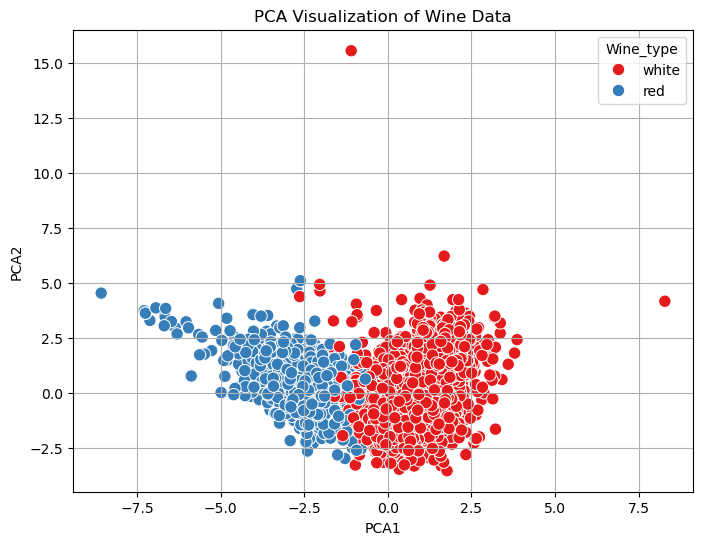

In [39]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df1,
    x="PC1",
    y="PC2",
    hue="Wine_type",
    palette="Set1",
    s=80
)
plt.title("PCA Visualization of Wine Data")
plt.xlabel("PCA1")
plt.ylabel("PCA2")
plt.grid()
plt.legend(title="Wine_type")
plt.show()